# Data Cleaning on the Titanic Dataset.

Steps covered in this notebook:

1. Load the data and inspect its structure (`info`, `describe`)
2. Check for missing values
3. Check for duplicate rows
4. Detect outliers using the IQR method (upper and lower bounds)
5. Handle outliers
6. Fix data types and engineer new features
7. Final check and save the cleaned data

## 1. Import Libraries

- `pandas` for working with tabular data
- `numpy` for numerical operations
- `matplotlib` and `seaborn` for plotting

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

## 2. Load the Data

The Titanic dataset ships with seaborn. Note that `sns.load_dataset` downloads the data the first time, so an internet connection is required.

In [3]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### Column Description

| Column | Meaning |
|---|---|
| survived | Survival (0 = No, 1 = Yes) |
| pclass | Ticket class (1, 2, 3) |
| sex | Gender |
| age | Age in years |
| sibsp | Number of siblings/spouses aboard |
| parch | Number of parents/children aboard |
| fare | Ticket fare |
| embarked | Port of embarkation code (C, Q, S) |
| class | Same as pclass but as text (First, Second, Third) |
| who | man / woman / child |
| adult_male | Whether the passenger is an adult male |
| deck | Deck of the cabin |
| embark_town | Full name of the embarkation port |
| alive | Same as survived but as yes/no |
| alone | Whether the passenger traveled alone |

## 3. Inspect the Structure of the Data

### 3.1 Shape
Number of rows (passengers) and columns (features).

In [4]:
print('Rows, columns:', df.shape)

Rows, columns: (891, 15)


### 3.2 `info()`
Shows column names, data types and the number of **non-null** values per column. If a column's non-null count is lower than the total number of rows, that column has missing values.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


### 3.3 `describe()` for Numeric Columns
Gives count, mean, standard deviation, minimum, quartiles (25%, 50%, 75%) and maximum.
Comparing the mean with the median (50%) and looking at `max` gives a first hint about outliers.

In [5]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


### 3.4 `describe()` for Categorical and Text Columns

In [10]:
df.describe(include=['str', 'category'])

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


### 3.5 Unique Values in Categorical Columns
This helps us spot unexpected values or typos.

In [11]:
for col in ['survived', 'pclass', 'sex', 'embarked', 'who', 'deck']:
    print(df[col].value_counts(dropna=False))
    print('-' * 30)

survived
0    549
1    342
Name: count, dtype: int64
------------------------------
pclass
3    491
1    216
2    184
Name: count, dtype: int64
------------------------------
sex
male      577
female    314
Name: count, dtype: int64
------------------------------
embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64
------------------------------
who
man      537
woman    271
child     83
Name: count, dtype: int64
------------------------------
deck
NaN    688
C       59
B       47
D       33
E       32
A       15
F       13
G        4
Name: count, dtype: int64
------------------------------


## 4. Check for Missing Values

We count and compute the percentage of missing values in each column.

In [12]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'count': missing, 'percent': missing_pct})
missing_df[missing_df['count'] > 0].sort_values('percent', ascending=False)

,count,percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22


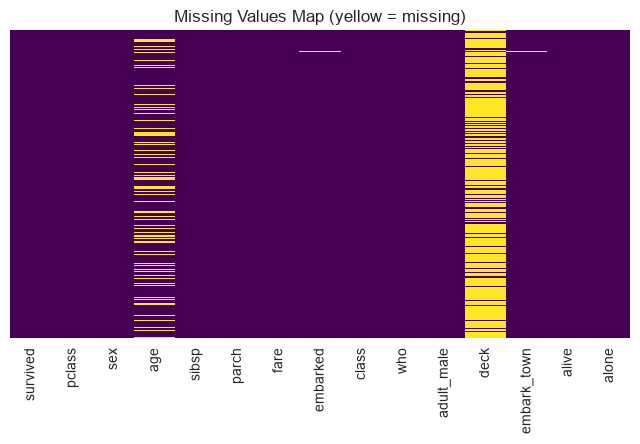

In [13]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap='viridis')
plt.title('Missing Values Map (yellow = missing)')
plt.show()

### Findings
- **deck**: about 77% missing. It is almost useless as-is, so we create a `has_deck` flag and drop the original column.
- **age**: about 20% missing. We fill it with the median.
- **embarked** and **embark_town**: 2 missing values each. We fill them with the mode (most frequent value).

## 5. Check for Duplicate Rows

**Note:** the seaborn version has no passenger ID or name column, so different passengers with identical feature values may be flagged as duplicates. We only inspect them here and then decide what to do.

In [14]:
print('Number of duplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Number of duplicate rows: 107


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
64,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
295,0,1,male,NaN,0,0,27.7208,C,First,man,True,NaN,Cherbourg,no,True
144,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
757,0,2,male,18.0,0,0,11.5000,S,Second,man,True,NaN,Southampton,no,True
658,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
733,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
734,0,2,male,23.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
134,0,2,male,25.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
343,0,2,male,25.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
666,0,2,male,25.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True


These rows are most likely different passengers who happen to share the same values, so we **do not drop them**. If your instructor wants duplicates removed, run:

`df = df.drop_duplicates()`

## 6. Fill Missing Values

### 6.1 Column `age`
We use the **median** because `age` contains outliers and is slightly skewed.
For better accuracy we compute the median **per group** of `pclass` and `sex` (for example, first-class passengers tend to be older than third-class ones).

In [15]:
print('Missing age before:', df['age'].isnull().sum())

df['age'] = df['age'].fillna(
    df.groupby(['pclass', 'sex'])['age'].transform('median')
)

print('Missing age after:', df['age'].isnull().sum())

Missing age before: 177
Missing age after: 0


### 6.2 Columns `embarked` and `embark_town` (mode)

In [16]:
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df['embark_town'] = df['embark_town'].fillna(df['embark_town'].mode()[0])
print(df[['embarked', 'embark_town']].isnull().sum())

embarked       0
embark_town    0
dtype: int64


### 6.3 Column `deck`
We create a new column `has_deck` (whether deck information was recorded) and then drop the original column.

In [17]:
df['has_deck'] = df['deck'].notnull().astype(int)
df = df.drop(columns=['deck'])
df.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    0
alive          0
alone          0
has_deck       0
dtype: int64

## 7. Detect Outliers with the IQR Method

- **Q1**: first quartile (25th percentile)
- **Q3**: third quartile (75th percentile)
- **IQR = Q3 - Q1**
- **Lower bound = Q1 - 1.5 x IQR**
- **Upper bound = Q3 + 1.5 x IQR**

Any value below the lower bound or above the upper bound is considered an outlier.

In [18]:
def iqr_bounds(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return Q1, Q3, IQR, lower, upper

for col in ['age', 'fare', 'sibsp', 'parch']:
    Q1, Q3, IQR, lower, upper = iqr_bounds(df[col])
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f'{col:6} | Q1={Q1:.2f} Q3={Q3:.2f} IQR={IQR:.2f} | '
          f'lower={lower:.2f} upper={upper:.2f} | outliers={n_out}')

age    | Q1=21.50 Q3=36.00 IQR=14.50 | lower=-0.25 upper=57.75 | outliers=33
fare   | Q1=7.91 Q3=31.00 IQR=23.09 | lower=-26.72 upper=65.63 | outliers=116
sibsp  | Q1=0.00 Q3=1.00 IQR=1.00 | lower=-1.50 upper=2.50 | outliers=46
parch  | Q1=0.00 Q3=0.00 IQR=0.00 | lower=0.00 upper=0.00 | outliers=213


### 7.1 Inspect the Outlier Rows
We filter the rows that fall outside the lower and upper bounds.

In [20]:
_, _, _, fare_low, fare_up = iqr_bounds(df['fare'])
fare_outliers = df[(df['fare'] < fare_low) | (df['fare'] > fare_up)]
print('Number of fare outliers:', len(fare_outliers))
fare_outliers[['pclass', 'sex', 'age', 'fare']].sort_values('fare', ascending=False).head(10)

Number of fare outliers: 116


,pclass,sex,age,fare
258,1,female,35.0,512.3292
737,1,male,35.0,512.3292
679,1,male,36.0,512.3292
27,1,male,19.0,263.0000
341,1,female,24.0,263.0000
438,1,male,64.0,263.0000
88,1,female,23.0,263.0000
311,1,female,18.0,262.3750
742,1,female,21.0,262.3750
299,1,female,50.0,247.5208


In [21]:
_, _, _, age_low, age_up = iqr_bounds(df['age'])
age_outliers = df[(df['age'] < age_low) | (df['age'] > age_up)]
print('Number of age outliers:', len(age_outliers))
age_outliers[['pclass', 'sex', 'age', 'fare']].sort_values('age', ascending=False).head(10)

Number of age outliers: 33


,pclass,sex,age,fare
630,1,male,80.0,30.0000
851,3,male,74.0,7.7750
96,1,male,71.0,34.6542
493,1,male,71.0,49.5042
116,3,male,70.5,7.7500
672,2,male,70.0,10.5000
745,1,male,70.0,71.0000
33,2,male,66.0,10.5000
456,1,male,65.0,26.5500
54,1,male,65.0,61.9792


### Analysis
- **fare** outliers are mostly first-class passengers who paid much more for their tickets. These values are **real**, not errors.
- **age** outliers are elderly passengers, which is perfectly plausible.

So instead of deleting them, we use **capping** so that no information is lost.

## 8. Handle Outliers

### Method 1: Capping
Values below the lower bound are set to the lower bound, and values above the upper bound are set to the upper bound. We store the result in new columns to keep the original data.

In [22]:
df['fare_capped'] = np.where(df['fare'] > fare_up, fare_up,
                     np.where(df['fare'] < fare_low, fare_low, df['fare']))

df['age_capped'] = np.where(df['age'] > age_up, age_up,
                    np.where(df['age'] < age_low, age_low, df['age']))

df[['fare', 'fare_capped', 'age', 'age_capped']].describe()

,fare,fare_capped,age,age_capped
count,891.000000,891.000000,891.000000,891.000000
mean,32.204208,24.046813,29.112424,28.893850
std,49.693429,20.481625,13.304424,12.732352
min,0.000000,0.000000,0.420000,0.420000
25%,7.910400,7.910400,21.500000,21.500000
50%,14.454200,14.454200,26.000000,26.000000
75%,31.000000,31.000000,36.000000,36.000000
max,512.329200,65.634400,80.000000,57.750000


### Method 2: Remove Outlier Rows 
Only appropriate when we are sure the outliers are errors. Here it is done on a separate copy for demonstration.

In [24]:
df_no_outlier = df[(df['fare'] >= fare_low) & (df['fare'] <= fare_up)]
print('Before removal:', len(df), '| After removal:', len(df_no_outlier))

Before removal: 891 | After removal: 775


## 9. Fix Data Types and Engineer Features

### 9.1 Convert Data Types

In [25]:
for col in ['survived', 'pclass', 'sex', 'embarked']:
    df[col] = df[col].astype('category')

df['alone'] = df['alone'].astype(int)
df['adult_male'] = df['adult_male'].astype(int)
df.dtypes

survived       category
pclass         category
sex            category
age             float64
sibsp             int64
parch             int64
fare            float64
embarked       category
class          category
who                 str
adult_male        int64
embark_town         str
alive               str
alone             int64
has_deck          int64
fare_capped     float64
age_capped      float64
fare_log        float64
dtype: object

### 9.2 Create New Columns
- `family_size` = sibsp + parch + 1
- `age_group` = age bins created with `pd.cut`

The `alone` column already exists in the dataset, so we do not recreate it.

In [26]:
df['family_size'] = df['sibsp'] + df['parch'] + 1

df['age_group'] = pd.cut(df['age'],
                         bins=[0, 12, 18, 35, 60, 120],
                         labels=['child', 'teen', 'young_adult', 'middle_aged', 'senior'])

df[['age', 'age_group', 'family_size', 'alone']].head()

,age,age_group,family_size,alone
0,22.0,young_adult,2,0
1,38.0,middle_aged,2,0
2,26.0,young_adult,1,1
3,35.0,young_adult,2,0
4,35.0,young_adult,1,1


### 9.3 Drop Redundant Columns
- `alive` carries the same information as `survived`.
- `class` carries the same information as `pclass`.
- `embark_town` carries the same information as `embarked`.

In [27]:
df_clean = df.drop(columns=['alive', 'class', 'embark_town'])
df_clean.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,who,adult_male,alone,has_deck,fare_capped,age_capped,fare_log,family_size,age_group
0,0,3,male,22.0,1,0,7.2500,S,man,1,0,0,7.2500,22.0,2.110213,2,young_adult
1,1,1,female,38.0,1,0,71.2833,C,woman,0,0,1,65.6344,38.0,4.280593,2,middle_aged
2,1,3,female,26.0,0,0,7.9250,S,woman,0,1,0,7.9250,26.0,2.188856,1,young_adult
3,1,1,female,35.0,1,0,53.1000,S,woman,0,0,1,53.1000,35.0,3.990834,2,young_adult
4,0,3,male,35.0,0,0,8.0500,S,man,1,1,0,8.0500,35.0,2.202765,1,young_adult


## 10. Final Check

In [28]:
print('Final shape:', df_clean.shape)
print('Total missing values:', df_clean.isnull().sum().sum())
df_clean.info()

Final shape: (891, 17)
Total missing values: 0
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 17 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    category
 1   pclass       891 non-null    category
 2   sex          891 non-null    category
 3   age          891 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     891 non-null    category
 8   who          891 non-null    str     
 9   adult_male   891 non-null    int64   
 10  alone        891 non-null    int64   
 11  has_deck     891 non-null    int64   
 12  fare_capped  891 non-null    float64 
 13  age_capped   891 non-null    float64 
 14  fare_log     891 non-null    float64 
 15  family_size  891 non-null    int64   
 16  age_group    891 non-null    category
dtypes: category(5), float64(5), int64(6),

## 11. Save the Cleaned Data

In [29]:
df_clean.to_csv('titanic_cleaned.csv', index=False)
print('Saved titanic_cleaned.csv')

Saved titanic_cleaned.csv


## Summary

| Step | What we did |
|---|---|
| Initial inspection | `shape`, `info`, `describe`, `value_counts` |
| Missing values | `age` filled with grouped median, `embarked` and `embark_town` with mode, `deck` dropped and replaced by `has_deck` |
| Duplicates | Inspected; not removed because the data has no passenger ID |
| Outliers | Detected with IQR (upper/lower bounds) and visualized with boxplots |
| Outlier handling | Capping and log transform |
| Data types | Converted to `category` and `int` |
| New features | `family_size`, `age_group`, `has_deck` |
| Redundant columns | Dropped `alive`, `class`, `embark_town` |